# Imports

In [1]:
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson
import networkx as nx            # samo za preverjanje rezultatov

rng = np.random.default_rng(1)

# Funkcije

In [2]:
class Graf:
    """Neusmerjen graf brez zank in večkratnih povezav (seznam sosednosti kot slovar množic)."""

    def __init__(self):
        self.sosedje = {}

    def dodaj_vozlisce(self, v):
        self.sosedje.setdefault(v, set())

    def dodaj_povezavo(self, u, v):
        if u == v:
            return
        self.dodaj_vozlisce(u)
        self.dodaj_vozlisce(v)
        self.sosedje[u].add(v)
        self.sosedje[v].add(u)

    def odstrani_povezavo(self, u, v):
        self.sosedje[u].discard(v)
        self.sosedje[v].discard(u)

    def odstrani_vozlisce(self, v):
        for u in self.sosedje.pop(v):
            self.sosedje[u].discard(v)

    def n(self):
        return len(self.sosedje)

    def m(self):
        return sum(len(s) for s in self.sosedje.values()) // 2

    def stopnja(self, v):
        return len(self.sosedje[v])

    def __repr__(self):
        return f"Graf(n={self.n()}, m={self.m()})"


def povprecna_stopnja(G):
    return 2 * G.m() / G.n()


def gostota(G):
    return 2 * G.m() / (G.n() * (G.n() - 1))


def lokalna_grucavost(G, v):
    """c_v = 2 e_v / (k_v (k_v - 1)); e_v je število povezav med sosedi v."""
    s = list(G.sosedje[v])
    k = len(s)
    if k < 2:
        return 0.0
    e = sum(1 for i in range(k) for j in range(i + 1, k) if s[j] in G.sosedje[s[i]])
    return 2 * e / (k * (k - 1))


def povprecna_grucavost(G):
    return np.mean([lokalna_grucavost(G, v) for v in G.sosedje])


def bfs(G, izvor):
    """Razdalje (število povezav) od izvora do vseh dosegljivih vozlišč."""
    d = {izvor: 0}
    vrsta = deque([izvor])
    while vrsta:
        u = vrsta.popleft()
        for w in G.sosedje[u]:
            if w not in d:
                d[w] = d[u] + 1
                vrsta.append(w)
    return d


def komponente(G):
    """Seznam povezanih komponent (množic vozlišč), od največje do najmanjše."""
    obiskana, komp = set(), []
    for v in G.sosedje:
        if v not in obiskana:
            c = set(bfs(G, v))
            obiskana |= c
            komp.append(c)
    return sorted(komp, key=len, reverse=True)


def razdalje(G):
    """Povprečna najkrajša pot L in premer grafa (na največji komponenti)."""
    gk = komponente(G)[0]
    vsota, parov, premer = 0, 0, 0
    for v in gk:
        d = bfs(G, v)
        vsota += sum(d.values())
        parov += len(d) - 1
        premer = max(premer, max(d.values()))
    return vsota / parov, premer


def nakljucni_graf(n, p, rng=rng):
    """Erdős-Rényijev graf G(n, p)."""
    G = Graf()
    for v in range(n):
        G.dodaj_vozlisce(v)
    for i in range(n):
        for j in range(i + 1, n):
            if rng.random() < p:
                G.dodaj_povezavo(i, j)
    return G


def obroc(n, k):
    """Pravilna obročasta mreža: vsako vozlišče je povezano s k/2 sosedi na vsaki strani."""
    G = Graf()
    for i in range(n):
        for j in range(1, k // 2 + 1):
            G.dodaj_povezavo(i, (i + j) % n)
    return G


def v_networkx(G):
    H = nx.Graph()
    H.add_nodes_from(G.sosedje)
    H.add_edges_from((u, v) for u in G.sosedje for v in G.sosedje[u])
    return H

# Testno območje

In [3]:
# Graf iz pripravljalne naloge P1
G1 = Graf()
for u, v in [(0, 1), (0, 2), (1, 2), (2, 3), (3, 4), (3, 5), (4, 5)]:
    G1.dodaj_povezavo(u, v)
G1.dodaj_povezavo(0, 1)    # podvojena povezava se ne sme šteti
G1.dodaj_povezavo(2, 2)    # zanka se ne sme dodati
print(G1, "| stopnje:", {v: G1.stopnja(v) for v in G1.sosedje})

Graf(n=6, m=7) | stopnje: {0: 2, 1: 2, 2: 3, 3: 3, 4: 2, 5: 2}


# Naloga 1

In [4]:
# Preglednica 1
print(f"n = {G1.n()}, m = {G1.m()}, <k> = {povprecna_stopnja(G1):.3f}, D = {gostota(G1):.3f}")
G2 = Graf()
for u in G1.sosedje:
    for v in G1.sosedje[u]:
        G2.dodaj_povezavo(u, v)
G2.odstrani_povezavo(2, 3)
G2.odstrani_vozlisce(5)
print("po odstranitvi:", G2, {v: sorted(s) for v, s in G2.sosedje.items()})

n = 6, m = 7, <k> = 2.333, D = 0.467
po odstranitvi: Graf(n=5, m=4) {0: [1, 2], 1: [0, 2], 2: [0, 1], 3: [4], 4: [3]}


# Naloga 2

In [5]:
print({v: round(lokalna_grucavost(G1, v), 3) for v in sorted(G1.sosedje)})
print(f"C = {povprecna_grucavost(G1):.4f}, networkx: {nx.average_clustering(v_networkx(G1)):.4f}")

{0: 1.0, 1: 1.0, 2: 0.333, 3: 0.333, 4: 1.0, 5: 1.0}
C = 0.7778, networkx: 0.7778


# Naloga 3

In [6]:
print("razdalje od 0:", bfs(G1, 0))
L1, D1 = razdalje(G1)
print(f"L = {L1:.4f}, premer = {D1}, networkx: {nx.average_shortest_path_length(v_networkx(G1)):.4f}")
G1.odstrani_povezavo(2, 3)
print("komponente:", komponente(G1))
G1.dodaj_povezavo(2, 3)

razdalje od 0: {0: 0, 1: 1, 2: 1, 3: 2, 4: 3, 5: 3}
L = 1.8000, premer = 3, networkx: 1.8000
komponente: [{0, 1, 2}, {3, 4, 5}]


# Naloga 4

In [7]:
n4 = 200
rezultati = []
for p in (0.01, 0.02, 0.05, 0.1):
    G = nakljucni_graf(n4, p)
    L, D = razdalje(G)
    k = povprecna_stopnja(G)
    print(f"G(n,p) p = {p:4}: <k> = {k:5.2f} (teor. {p*(n4-1):5.2f}), C = {povprecna_grucavost(G):.3f} (teor. {p}), "
          f"L = {L:.2f} (teor. {np.log(n4)/np.log(k):.2f}), največja komp. = {len(komponente(G)[0])}")
for k in (4, 10):
    G = obroc(n4, k)
    L, D = razdalje(G)
    print(f"obroč k = {k:2d}: <k> = {povprecna_stopnja(G):.2f}, C = {povprecna_grucavost(G):.3f} "
          f"(teor. {3*(k-2)/(4*(k-1)):.3f}), L = {L:.2f} (teor. {n4/(2*k):.2f}), premer = {D}")

G(n,p) p = 0.01: <k> =  1.85 (teor.  1.99), C = 0.013 (teor. 0.01), L = 8.25 (teor. 8.61), največja komp. = 153
G(n,p) p = 0.02: <k> =  4.22 (teor.  3.98), C = 0.020 (teor. 0.02), L = 3.80 (teor. 3.68), največja komp. = 198


G(n,p) p = 0.05: <k> =  9.93 (teor.  9.95), C = 0.054 (teor. 0.05), L = 2.55 (teor. 2.31), največja komp. = 200

G(n,p) p =  0.1: <k> = 19.61 (teor. 19.90), C = 0.100 (teor. 0.1), L = 2.03 (teor. 1.78), največja komp. = 200
obroč k =  4: <k> = 4.00, C = 0.500 (teor. 0.500), L = 25.38 (teor. 25.00), premer = 50
obroč k = 10: <k> = 10.00, C = 0.667 (teor. 0.667), L = 10.45 (teor. 10.00), premer = 20


# Naloga 4 - Slika 1

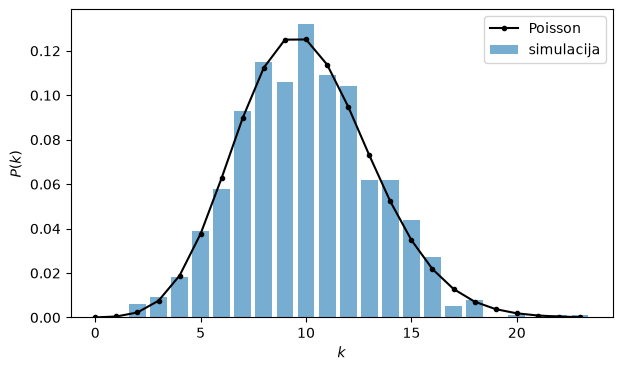

In [8]:
G = nakljucni_graf(1000, 0.01)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
st = np.array([G.stopnja(v) for v in G.sosedje])
k_v, N_k = np.unique(st, return_counts=True)
ax.bar(k_v, N_k / len(st), color="tab:blue", alpha=0.6, label="simulacija")
kk = np.arange(st.max() + 1)
ax.plot(kk, poisson.pmf(kk, st.mean()), "ko-", ms=3, label="Poisson")
ax.set_xlabel("$k$")
ax.set_ylabel("$P(k)$")
ax.legend()
plt.show()